### Домашнє завдання: Кластеризація в Аналізі Персоналій Клієнтів

#### Контекст
В цьому ДЗ ми скористаємось алгоритмами кластеризації для задачі аналізу портретів клієнтів (Customer Personality Analysis).

Customer Personality Analysis - це аналіз різних сегментів клієнтів компанії. Цей аналіз дозволяє бізнесу краще розуміти своїх клієнтів і полегшує процес адаптації продуктів під конкретні потреби, поведінку та інтереси різних типів клієнтів.

Аналіз портретів клієнтів допомагає бізнесу змінювати свій продукт на основі цільової аудиторії, розділеної на різні сегменти. Наприклад, замість того, щоб витрачати гроші на маркетинг нового продукту для всіх клієнтів у базі даних компанії, бізнес може проаналізувати, який сегмент клієнтів найімовірніше придбає продукт, і потім зосередити маркетингові зусилля лише на цьому сегменті.

#### Завдання
На основі наданих даних в файлі `marketing_campaign.csv` потрібно виконати кластеризацію, щоб виявити сегменти клієнтів.

#### Вхідні дані
Вам надано набір даних з такими атрибутами:

**Характеристики користувачів:**
- `ID`: Унікальний ідентифікатор клієнта
- `Year_Birth`: Рік народження клієнта
- `Education`: Рівень освіти клієнта
- `Marital_Status`: Сімейний стан клієнта
- `Income`: Річний дохід домогосподарства клієнта
- `Kidhome`: Кількість дітей у домогосподарстві клієнта
- `Teenhome`: Кількість підлітків у домогосподарстві клієнта
- `Dt_Customer`: Дата реєстрації клієнта у компанії
- `Recency`: Кількість днів з моменту останньої покупки клієнта
- `Complain`: 1, якщо клієнт скаржився за останні 2 роки, 0 - якщо ні

**Продукти:**
- `MntWines`: Сума, витрачена на вино за останні 2 роки
- `MntFruits`: Сума, витрачена на фрукти за останні 2 роки
- `MntMeatProducts`: Сума, витрачена на м'ясні продукти за останні 2 роки
- `MntFishProducts`: Сума, витрачена на рибні продукти за останні 2 роки
- `MntSweetProducts`: Сума, витрачена на солодощі за останні 2 роки
- `MntGoldProds`: Сума, витрачена на золото за останні 2 роки

**Акції:**
- `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
- `AcceptedCmp1`: 1, якщо клієнт прийняв пропозицію у першій кампанії, 0 - якщо ні
- `AcceptedCmp2`: 1, якщо клієнт прийняв пропозицію у другій кампанії, 0 - якщо ні
- `AcceptedCmp3`: 1, якщо клієнт прийняв пропозицію у третій кампанії, 0 - якщо ні
- `AcceptedCmp4`: 1, якщо клієнт прийняв пропозицію у четвертій кампанії, 0 - якщо ні
- `AcceptedCmp5`: 1, якщо клієнт прийняв пропозицію у п'ятій кампанії, 0 - якщо ні
- `Response`: 1, якщо клієнт прийняв пропозицію в останній кампанії, 0 - якщо ні

**Взаємодія з компанією:**
- `NumWebPurchases`: Кількість покупок, зроблених через вебсайт компанії
- `NumCatalogPurchases`: Кількість покупок, зроблених за каталогом
- `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
- `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць


**Завдання 1**. Завантажте дані з `marketing_campaign.csv` в Pandas dataframe і виведіть основну інформацію про дані: скільки всього рядків і колонок, які типи даних мають колонки, скільки пропущених значень.

In [5]:
import os
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

data_dir = '/content/drive/MyDrive/ML1/data/'
print(os.listdir(data_dir))          # спершу дивлюсь, що в теці


Mounted at /content/drive
['credit', 'cars.csv', 'medical-charges.csv', 'workdata', 'kaggle_data', 'estimation_of_obesity_levels_based_on_eating_habits_and_physical.csv', 'regression_data.csv', 'customer_segmentation_train.csv', 'bank-additional-full.csv', 'bank_additional_full.xlsx', 'marketing_campaign.csv']


In [6]:
# Файл розділений табуляцією. Без sep='\t' буде одна колонка і код не впаде
df_raw = pd.read_csv(data_dir + 'marketing_campaign.csv', sep='\t')

print('рядків і колонок:', df_raw.shape)

рядків і колонок: (2240, 29)


In [7]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [8]:
# Пропуски: тільки там, де вони є
na = df_raw.isna().sum()
print('колонки з пропусками:')
print(na[na > 0].to_string())
print('\nусього пропущених значень:', int(na.sum()))
print('частка рядків з пропуском: %.3f %%' % (100 * df_raw.isna().any(axis=1).mean()))

колонки з пропусками:
Income    24

усього пропущених значень: 24
частка рядків з пропуском: 1.071 %


In [9]:
# Типи по групах і перші рядки нечислових колонок
print(df_raw.dtypes.value_counts().to_string())
obj_cols = df_raw.dtypes[df_raw.dtypes == 'object'].index.tolist()
print('\nнечислові колонки:', obj_cols)
print(df_raw[obj_cols].head())

int64      25
object      3
float64     1

нечислові колонки: ['Education', 'Marital_Status', 'Dt_Customer']
    Education Marital_Status Dt_Customer
0  Graduation         Single  04-09-2012
1  Graduation         Single  08-03-2014
2  Graduation       Together  21-08-2013
3  Graduation       Together  10-02-2014
4         PhD        Married  19-01-2014


In [10]:
# describe: шукаю нульову дисперсію і неправдоподібні межі
desc = df_raw.describe().T[['min', 'max', 'mean', 'std']]
print(desc.round(2).to_string())
print('\nколонки з нульовою дисперсією:',
      [c for c in df_raw.columns if df_raw[c].nunique() == 1])

                        min       max      mean       std
ID                      0.0   11191.0   5592.16   3246.66
Year_Birth           1893.0    1996.0   1968.81     11.98
Income               1730.0  666666.0  52247.25  25173.08
Kidhome                 0.0       2.0      0.44      0.54
Teenhome                0.0       2.0      0.51      0.54
Recency                 0.0      99.0     49.11     28.96
MntWines                0.0    1493.0    303.94    336.60
MntFruits               0.0     199.0     26.30     39.77
MntMeatProducts         0.0    1725.0    166.95    225.72
MntFishProducts         0.0     259.0     37.53     54.63
MntSweetProducts        0.0     263.0     27.06     41.28
MntGoldProds            0.0     362.0     44.02     52.17
NumDealsPurchases       0.0      15.0      2.33      1.93
NumWebPurchases         0.0      27.0      4.08      2.78
NumCatalogPurchases     0.0      28.0      2.66      2.92
NumStorePurchases       0.0      13.0      5.79      3.25
NumWebVisitsMo

Файл розділений табуляцією, тому читаю його з sep='\t'. Датафрейм має 2240 рядків і 29 колонок. Нечислових колонок 3: Education, Marital_Status (категорії) і Dt_Customer (дата, прочитана як рядок). Пропуски є лише в одній колонці, Income. Колонки Z_CostContact і Z_Revenue мають однакове значення на всіх рядках, тобто нульову дисперсію, і для кластеризації марні. ID числовий, але це ключ, а не ознака.

**Завдання 2.** Заповніть пропущені значення з врахуванням того завдання (кластеризація), яке ми виконуємо. Поясніть свій вибір заповнення пропущених значень.

In [11]:
# МОЄ РІШЕННЯ: видаляю 24 рядки з пропуском в Income.
# Чому: це 1.07 % даних, і будь-яке заповнення центральним значенням
# поставило б 24 клієнти рівно в середину головної осі (Income тримає майже всю сиру дисперсію), тобто приписало б їм членство в кластері.

df = df_raw.dropna(subset=['Income']).reset_index(drop=True)

print('рядків було:', len(df_raw))
print('рядків стало:', len(df))
print('пропусків після:', int(df.isna().sum().sum()))
print('Income: mean %.2f, median %.1f, sd %.2f'
      % (df['Income'].mean(), df['Income'].median(), df['Income'].std(ddof=0)))

рядків було: 2240
рядків стало: 2216
пропусків після: 0
Income: mean 52247.25, median 51381.5, sd 25167.40


**Завдання 3.** У нас є декілька колонок з категоріальними значеннями та одна колонка з датою. Як би ви обробили ці колонки для того, аби передати їх в алгоритм кластеризації?

Реалізуйте обробку категоріальних колонок і колонки з датою та перетворіть їх на ознаки, корисні для кластеризації з вашого погляду.

In [12]:
# МОЇ РІШЕННЯ:
#   Marital_Status -> одна бінарна ознака HasPartner (Married, Together = 1)
#   Education      -> one-hot, 5 колонок
#   Dt_Customer    -> стаж у днях від фіксованої дати знімка

# 1. Дата. format обов'язковий: у файлі dd-mm-yyyy
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
snapshot = df['Dt_Customer'].max()          # фіксована дата, не today()
df['Customer_Days'] = (snapshot - df['Dt_Customer']).dt.days

print('дата знімка:', snapshot.date())
print('дата реєстрації від', df['Dt_Customer'].min().date(),
      'до', df['Dt_Customer'].max().date())
print(df['Customer_Days'].describe().round(1).to_string())

дата знімка: 2014-06-29
дата реєстрації від 2012-07-30 до 2014-06-29
count    2216.0
mean      353.5
std       202.4
min         0.0
25%       180.0
50%       355.5
75%       529.0
max       699.0


In [13]:
# 2. Marital_Status -> HasPartner
print('до перетворення:')
print(df['Marital_Status'].value_counts().to_string())

# прибираю Absurd і YOLO:
df = df[~df['Marital_Status'].isin(['Absurd', 'YOLO'])].reset_index(drop=True)

df['HasPartner'] = df['Marital_Status'].isin(['Married', 'Together']).astype(int)

print('\nHasPartner:', df['HasPartner'].value_counts().to_dict())
print('що потрапило в 0:',
      df.loc[df['HasPartner'] == 0, 'Marital_Status'].value_counts().to_dict())

до перетворення:
Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2

HasPartner: {1: 1430, 0: 782}
що потрапило в 0: {'Single': 471, 'Divorced': 232, 'Widow': 76, 'Alone': 3}


In [14]:
# 3. Education -> one-hot
edu_dummies = pd.get_dummies(df['Education'], prefix='Edu').astype(int)
df = pd.concat([df, edu_dummies], axis=1)

print(edu_dummies.sum().to_string())
print('\nсума по рядку завжди 1:', edu_dummies.sum(axis=1).unique())

Edu_2n Cycle       200
Edu_Basic           54
Edu_Graduation    1115
Edu_Master         364
Edu_PhD            479

сума по рядку завжди 1: [1]


In [16]:
# --- Перевірка: який z отримає одиниця в кожній бінарній колонці після StandardScaler
bin_cols = [c for c in df.columns
            if df[c].dropna().isin([0, 1]).all() and df[c].nunique() == 2]

chk = pd.DataFrame({'ones': df[bin_cols].sum()})
chk['p'] = (chk['ones'] / len(df)).round(5)
chk['z_for_1'] = np.sqrt((1 - chk['p']) / chk['p']).round(2)
print(chk.sort_values('ones').to_string())

                ones        p  z_for_1
Complain          21  0.00949    10.22
AcceptedCmp2      30  0.01356     8.53
Edu_Basic         54  0.02441     6.32
AcceptedCmp1     141  0.06374     3.83
AcceptedCmp5     161  0.07278     3.57
AcceptedCmp3     163  0.07369     3.55
AcceptedCmp4     164  0.07414     3.53
Edu_2n Cycle     200  0.09042     3.17
Response         331  0.14964     2.38
Edu_Master       364  0.16456     2.25
Edu_PhD          479  0.21655     1.90
Edu_Graduation  1115  0.50407     0.99
HasPartner      1430  0.64647     0.74


**Завдання 4**.
1. Запишіть в змінну X ті дані, які будете кластеризувати.
2. Побудуйте кластеризацію з KMeans на 3 кластери.
3. Обчисліть метрику силуету для цієї кластеризації.

In [18]:
# МОЄ РІШЕННЯ:
# склад X = поведінка + демографія, без кампаній, Complain і Customer_Days.
# дублікати прибрані в попередній клітинці (182 рядки, лишилось 2030).

feat_behaviour = [
    'Income', 'Recency',
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases',
    'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
]
feat_demo = ['Year_Birth', 'Kidhome', 'Teenhome', 'HasPartner'] + \
            [c for c in df.columns if c.startswith('Edu_')]

X_cols = feat_behaviour + feat_demo
X = df[X_cols].copy()

print('X:', X.shape)
print('колонки:', X_cols)
print('NaN:', int(X.isna().sum().sum()),
      ', нульова дисперсія:', [c for c in X_cols if X[c].nunique() == 1])

X: (2030, 22)
колонки: ['Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Year_Birth', 'Kidhome', 'Teenhome', 'HasPartner', 'Edu_2n Cycle', 'Edu_Basic', 'Edu_Graduation', 'Edu_Master', 'Edu_PhD']
NaN: 0 , нульова дисперсія: []


In [19]:
# Частка сирої дисперсії по колонках: хто насправді керує відстанню
var = X.var(ddof=0)
print((var / var.sum()).sort_values(ascending=False).round(6).to_string())

Income                 0.999731
MntWines               0.000175
MntMeatProducts        0.000079
MntFishProducts        0.000005
MntGoldProds           0.000004
MntSweetProducts       0.000003
MntFruits              0.000002
Recency                0.000001
Year_Birth             0.000000
NumStorePurchases      0.000000
NumCatalogPurchases    0.000000
NumWebPurchases        0.000000
NumWebVisitsMonth      0.000000
NumDealsPurchases      0.000000
Teenhome               0.000000
Kidhome                0.000000
Edu_Graduation         0.000000
HasPartner             0.000000
Edu_PhD                0.000000
Edu_Master             0.000000
Edu_2n Cycle           0.000000
Edu_Basic              0.000000


In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km3_raw = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_km3_raw = km3_raw.fit_predict(X)

sil_km3_raw = silhouette_score(X, labels_km3_raw)
print('силует, k=3, без масштабування: %.4f' % sil_km3_raw)
print('WSS (inertia): %.4e' % km3_raw.inertia_)
print('розміри кластерів:',
      pd.Series(labels_km3_raw).value_counts().sort_index().to_dict())

силует, k=3, без масштабування: 0.6014
WSS (inertia): 3.0086e+11
розміри кластерів: {0: 1038, 1: 991, 2: 1}


In [21]:
# Що це за кластери: медіани в сирих одиницях і межі по Income
df['cluster_km3_raw'] = labels_km3_raw

prof_raw = df.groupby('cluster_km3_raw')[['Income', 'MntWines', 'MntMeatProducts',
                                          'NumStorePurchases', 'NumWebPurchases']].median()
prof_raw['n'] = df['cluster_km3_raw'].value_counts().sort_index()
print(prof_raw.round(1).to_string())

print('\nmin і max Income у кожному кластері:')
print(df.groupby('cluster_km3_raw')['Income'].agg(['min', 'max']).to_string())

                   Income  MntWines  MntMeatProducts  NumStorePurchases  NumWebPurchases     n
cluster_km3_raw                                                                               
0                 35790.5      25.0             17.5                3.0              2.0  1038
1                 69096.0     496.0            231.0                8.0              5.0   991
2                666666.0       9.0             18.0                3.0              3.0     1

min і max Income у кожному кластері:
                      min       max
cluster_km3_raw                    
0                  1730.0   52413.0
1                 52513.0  162397.0
2                666666.0  666666.0


У X я взяла 22 колонки: поведінку з магазином і демографію.

ID, Z_CostContact, Z_Revenue і колонки кампаній я виключила. Перед цим я прибрала 182 повні дублікати (без ID), бо KMeans зважує точку за кратністю і копії тягнуть центроїд. Лишилось 2030 рядків.

KMeans на 3 кластери без масштабування дав силует 0.6014 і розміри 1038, 991, 1.

Число виглядає добрим, але воно оманливе. Колонка Income тримає 99.97 % сирої дисперсії X, тож решта 21 колонка арифметично невидима, і кластеризація фактично пройшла по одній осі.

Третій кластер це один клієнт з доходом 666666. Межа між двома великими кластерами лягла на 52413, тобто приблизно на медіану доходу, хоча жодного розриву в розподілі там немає.

**Висновок:** без масштабування це не сегментація клієнтів, а розріз доходу навпіл плюс один викид.

**Завдання 5.** Візуалізуйте знайдені кластери разом з наявними даними та проаналізуйте кластери. У нас ознак більше, ніж 2 або 3, тож, тут треба подумати, які саме ознаки варто використати для візуалізації аби вони були інформативними. Рекомендую точно звернути увагу на харакетиристики про дохід користувачів і те, як вони взаємодять з магазинок (кількість покупок і тд).

Для візуалізації зручно може бути використати `plotly.express.scatter_3d` для 3D графіку розсіювання, але тут можна скористатись будь-яким зрозумілим і зручним для вас методом візуалізації. Опишіть свої спостереження, чи кластери мають сенс?

In [22]:
import plotly.express as px

# Похідні колонки тільки для візуалізації, у X вони не входять
mnt_cols = [c for c in df.columns if c.startswith('Mnt')]
df['TotalMnt'] = df[mnt_cols].sum(axis=1)
df['TotalPurchases'] = (df['NumWebPurchases'] + df['NumCatalogPurchases']
                        + df['NumStorePurchases'])

fig = px.scatter_3d(
    df, x='Income', y='TotalPurchases', z='TotalMnt',
    color=df['cluster_km3_raw'].astype(str),
    opacity=0.6, height=650,
    title='Кластери KMeans k=3 без масштабування (з викидом)',
    labels={'color': 'кластер'},
)
fig.update_traces(marker=dict(size=3))
fig.show()

In [23]:
# Той самий графік без викиду: видно, де насправді пройшла межа
mask_no_out = df['Income'] < 200000
fig2 = px.scatter_3d(
    df[mask_no_out], x='Income', y='TotalPurchases', z='TotalMnt',
    color=df.loc[mask_no_out, 'cluster_km3_raw'].astype(str),
    opacity=0.6, height=650,
    title='Те саме без викиду Income 666666',
    labels={'color': 'кластер'},
)
fig2.update_traces(marker=dict(size=3))
fig2.show()

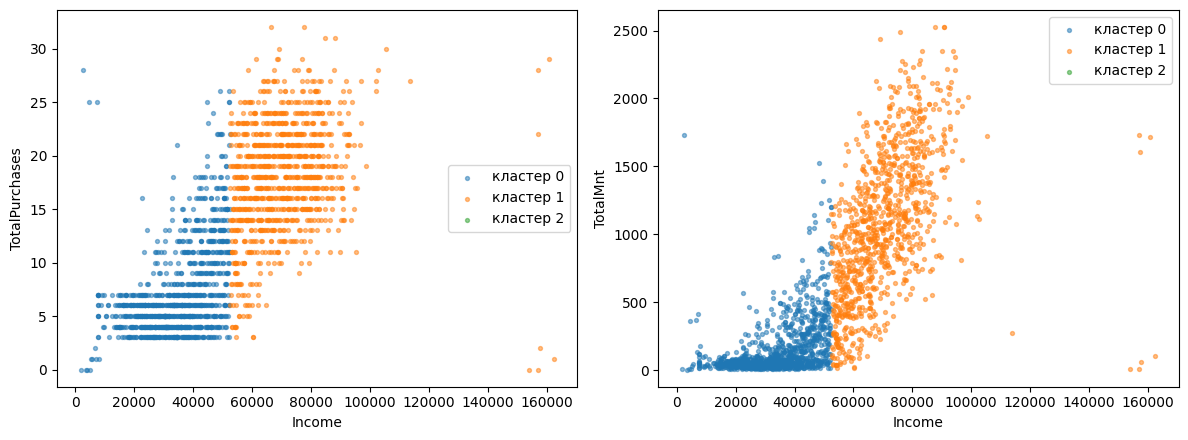

In [24]:
# Пласкі зрізи: інколи читабельніші за 3D
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (xc, yc) in zip(axes, [('Income', 'TotalPurchases'),
                               ('Income', 'TotalMnt')]):
    for c in sorted(df['cluster_km3_raw'].unique()):
        sub = df[(df['cluster_km3_raw'] == c) & mask_no_out]
        ax.scatter(sub[xc], sub[yc], s=8, alpha=0.5, label='кластер %d' % c)
    ax.set_xlabel(xc)
    ax.set_ylabel(yc)
    ax.legend()
plt.tight_layout()
plt.show()

In [25]:
# Профіль кластерів у сирих одиницях, щоб словами описати спостереження
prof5 = df.groupby('cluster_km3_raw')[
    ['Income', 'TotalMnt', 'TotalPurchases', 'NumWebVisitsMonth',
     'Kidhome', 'Teenhome', 'Year_Birth', 'Recency']].median()
prof5['n'] = df['cluster_km3_raw'].value_counts().sort_index()
print(prof5.round(1).to_string())

                   Income  TotalMnt  TotalPurchases  NumWebVisitsMonth  Kidhome  Teenhome  Year_Birth  Recency     n
cluster_km3_raw                                                                                                     
0                 35790.5      72.0             6.0                7.0      1.0       0.0      1972.0     49.0  1038
1                 69096.0    1048.0            18.0                4.0      0.0       1.0      1967.0     50.0   991
2                666666.0      62.0             7.0                6.0      1.0       0.0      1977.0     23.0     1


Для візуалізації я взяла Income проти TotalPurchases і проти TotalMnt (суми шести колонок Mnt*). Пласкі зрізи виявились читабельнішими за scatter_3d, бо третя вісь приховувала межу.

Кластери мають сенс лише на перший погляд. Профіль виглядає як готова сегментація: кластер 0 має медіанний дохід 35790, витрати 72 і 6 покупок, кластер 1 має 69096, 1048 і 18 покупок. Але на графіку межа між ними строго вертикальна при Income близько 52450. Жодна інша ознака в поділі не брала участі. Є сині точки з витратами 1700 і помаранчеві з витратами біля нуля: вони розділені тільки доходом.

Отже кластери відтворюють кореляцію доходу з витратами, а не сегменти поведінки. Третій кластер це один клієнт з доходом 666666, який витрачає як найбідніші, тобто помилка введення. На правому краю видно ще сім рядків з доходом 154 до 162 тисяч при 99-му процентилі 94593.

**Завдання 6**. Масштабуйте дані (StandardScaler/MinMaxScaler) і побудуйте знову кластеризацію KMeans на 3 кластери і обчисліть метрику силуету. Опишіть порівняння з експериментом без масштабування значень.

In [26]:
from sklearn.preprocessing import StandardScaler

scaler_v1 = StandardScaler()                 # fit на тих самих 2030 рядках
X_scaled_v1 = scaler_v1.fit_transform(X)

print('X_scaled_v1:', X_scaled_v1.shape)
print('перевірка: середні близько 0:', np.abs(X_scaled_v1.mean(axis=0)).max().round(10))
print('перевірка: sd = 1:', X_scaled_v1.std(axis=0).round(6)[:5], '...')
print('найбільше значення в масштабованих даних: %.2f' % X_scaled_v1.max())

X_scaled_v1: (2030, 22)
перевірка: середні близько 0: 0.0
перевірка: sd = 1: [1. 1. 1. 1. 1.] ...
найбільше значення в масштабованих даних: 24.06


In [27]:
km3_scaled = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_km3_scaled = km3_scaled.fit_predict(X_scaled_v1)

sil_km3_scaled = silhouette_score(X_scaled_v1, labels_km3_scaled)
print('силует, k=3, StandardScaler: %.4f' % sil_km3_scaled)
print('силует, k=3, без масштабування: %.4f' % sil_km3_raw)
print('розміри кластерів:',
      pd.Series(labels_km3_scaled).value_counts().sort_index().to_dict())

силует, k=3, StandardScaler: 0.1516
силует, k=3, без масштабування: 0.6014
розміри кластерів: {0: 577, 1: 914, 2: 539}


In [28]:
# Що тепер розділяє кластери: центроїди назад у сирі одиниці
centers_raw = pd.DataFrame(
    scaler_v1.inverse_transform(km3_scaled.cluster_centers_), columns=X_cols)
print(centers_raw.round(1).T.to_string())

                           0        1        2
Income               57677.4  34485.5  76910.1
Recency                 48.9     49.1     48.5
MntWines               458.4     38.8    592.5
MntFruits               19.7      4.9     69.5
MntMeatProducts        130.1     22.8    453.9
MntFishProducts         27.5      7.0     99.2
MntSweetProducts        19.9      5.1     72.4
MntGoldProds            58.4     15.3     75.9
NumDealsPurchases        3.7      2.0      1.4
NumWebPurchases          6.2      2.1      5.2
NumCatalogPurchases      3.0      0.5      6.0
NumStorePurchases        7.5      3.2      8.4
NumWebVisitsMonth        5.7      6.5      2.9
Year_Birth            1964.3   1972.0   1968.2
Kidhome                  0.2      0.8      0.0
Teenhome                 0.9      0.4      0.2
HasPartner               0.7      0.6      0.6
Edu_2n Cycle             0.1      0.1      0.1
Edu_Basic                0.0      0.1      0.0
Edu_Graduation           0.4      0.5      0.6
Edu_Master   

In [29]:
# Наскільки різні два розбиття: ARI як міра згоди
from sklearn.metrics import adjusted_rand_score
print('ARI між розбиттям без масштабування і з масштабуванням: %.3f'
      % adjusted_rand_score(labels_km3_raw, labels_km3_scaled))

ARI між розбиттям без масштабування і з масштабуванням: 0.458


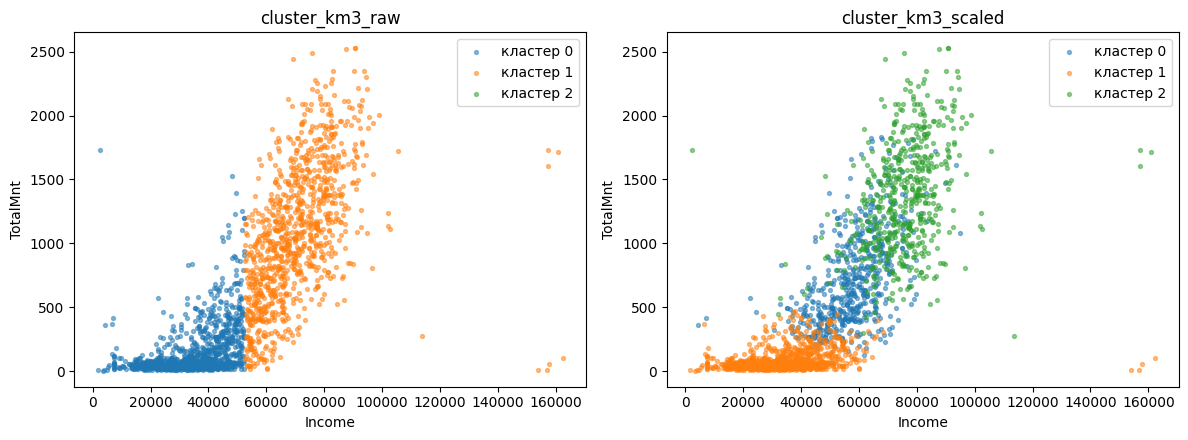

In [30]:
df['cluster_km3_scaled'] = labels_km3_scaled

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ['cluster_km3_raw', 'cluster_km3_scaled']):
    for c in sorted(df[col].unique()):
        sub = df[(df[col] == c) & mask_no_out]
        ax.scatter(sub['Income'], sub['TotalMnt'], s=8, alpha=0.5, label='кластер %d' % c)
    ax.set_title(col)
    ax.set_xlabel('Income')
    ax.set_ylabel('TotalMnt')
    ax.legend()
plt.tight_layout()
plt.show()

Я взяла StandardScaler, бо MinMaxScaler при наявному викиді 666666 стиснув би всі реальні доходи в чверть діапазону: один рядок визначав би масштаб колонки. Скейлер я навчила на тих самих 2030 рядках, які кластеризую.

Силует упав з 0.6014 до 0.1516. Це не погіршення: силует міряє розділення в тому просторі, який йому дали, і два простори різні. Без масштабування простір був фактично одновимірним (Income тримав 99.97 % дисперсії), тож дві щільні групи на прямій давали високу оцінку. Після масштабування працюють усі 22 виміри, точки розкидані по хмарі без порожніх прошарків, і в багатьох вимірах попарні відстані зближуються, тож силует природно малий.

Змістовно результат протилежний.

Викид 666666 більше не займає власний кластер: по 21 з 22 осей цей клієнт звичайний.

Межі на графіку стали похилими, а не вертикальними.
Кластери розділились за доходом і поведінкою: 34485 / 95 витрат / 6.5 візиту на сайт; 57677 / 714 / 3.7 покупки за акцією; 76910 / 1363 / 6.0 покупки з каталогу. ARI між двома розбиттями 0.458, тобто це інші кластери, а не ті самі під іншими номерами.

Правило, яке я звідси забираю: силует порівнюють тільки всередині одного простору ознак.

**Завдання 7.** З візуалізацій на попередньому кроці ви могли побачити якісь викиди в даних. Опрацюйте викиди (можна видалити ці рядки або придумати інший спосіб).

In [31]:
# МОЄ РІШЕННЯ:
# Видаляю викиди Income за межею Тьюкі (Q3 + 1.5 * IQR) і трьох клієнтів з Year_Birth < 1940.
# Чому: межа Тьюкі це правило на квартилях, яке сам викид не зсуває,
# а вік 120+ років неможливий фізично.
# Правило |z| > 3 я відхилила: воно позначає 242 рядки (11.9 %), бо колонки Mnt* мають довгий правий хвіст з реальних покупців, а не з помилок.

q1, q3 = df['Income'].quantile([0.25, 0.75])
hi_fence = q3 + 1.5 * (q3 - q1)
print('межа Тьюкі для Income: %.0f' % hi_fence)

mask_keep = (df['Income'] <= hi_fence) & (df['Year_Birth'] >= 1940)
df_clean = df[mask_keep].reset_index(drop=True)

print('рядків було %d, стало %d, видалено %d'
      % (len(df), len(df_clean), len(df) - len(df_clean)))
print('Income: середнє %.1f -> %.1f' % (df['Income'].mean(), df_clean['Income'].mean()))
print('Income: sd %.1f -> %.1f'
      % (df['Income'].std(ddof=0), df_clean['Income'].std(ddof=0)))

межа Тьюкі для Income: 118010
рядків було 2030, стало 2019, видалено 11
Income: середнє 52341.9 -> 51659.7
Income: sd 25536.9 -> 20710.3


In [32]:
# Скейлер вчиться ЗАНОВО на нових рядках. Новий об'єкт, нове ім'я.
# scaler_v1 знає середнє і sd розподілу з викидами, тому тут не годиться.
from sklearn.preprocessing import StandardScaler

X_clean = df_clean[X_cols].copy()
scaler_v2 = StandardScaler()
X_scaled_v2 = scaler_v2.fit_transform(X_clean)

print('X_clean:', X_clean.shape)
print('найбільше значення після масштабування: %.2f (було 24.06)' % X_scaled_v2.max())

X_clean: (2019, 22)
найбільше значення після масштабування: 9.07 (було 24.06)


In [33]:
km3_clean = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_km3_clean = km3_clean.fit_predict(X_scaled_v2)

sil_km3_clean = silhouette_score(X_scaled_v2, labels_km3_clean)
print('силует k=3: без викидів %.4f, з викидами %.4f'
      % (sil_km3_clean, sil_km3_scaled))
print('розміри:', pd.Series(labels_km3_clean).value_counts().sort_index().to_dict())

силует k=3: без викидів 0.1573, з викидами 0.1516
розміри: {0: 900, 1: 537, 2: 582}


Я застосувала межу Тьюкі до Income (Q3 + 1.5 * IQR дорівнює 118010) і прибрала трьох клієнтів з Year_Birth < 1940 (1893, 1899, 1900), тобто віком понад 120 років. Разом 11 рядків з 2030, лишилось 2019.

Межу Тьюкі я обрала тому, що вона будується на квартилях, а їх сам викид не зсуває. Правило |z| > 3 я перевірила і відхилила: воно позначає 242 рядки (11.9 %), бо колонки Mnt* мають довгий правий хвіст з реальних покупців, а не з помилок. Викид 666666 додатково підтверджений як помилка введення: цей клієнт витратив на вино 9 і зробив 3 покупки, тобто поводиться як найбідніший сегмент.

Скейлер я навчила заново (scaler_v2) на 2019 рядках. Застосувати scaler_v1 було б помилкою: він пам'ятає середнє і sd розподілу з викидами.

Результат: sd Income впала з 25536.9 до 20710.3 (на 19%), найбільше значення в масштабованих даних з 24.06 до 9.07. Силует k = 3 майже не змінився, 0.1573 проти 0.1516. Викиди псували не метрику, а систему координат: тепер z по осі доходу означає інше.

**Завдання 8.** Виконайте Elbow method для пошуку оптимальної кількості кластерів та натренуйте KMeans з тою кількістю кластерів, яку Elbow method показав як оптимальну. Обчисліть метрику силуету. Візуалізуйте кластери. З яким набором даних (масштабованим чи ні) тут працювати - ваш вибір, можна зробити експеримент з обома.

In [34]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

ks = range(2, 11)
rows = []
for k in ks:
    km_a = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled_v2)
    lab_b = KMeans(n_clusters=k, n_init=10, random_state=7).fit_predict(X_scaled_v2)
    rows.append({
        'k': k,
        'WSS': km_a.inertia_,
        'silhouette': silhouette_score(X_scaled_v2, km_a.labels_),
        'calinski_harabasz': calinski_harabasz_score(X_scaled_v2, km_a.labels_),
        'davies_bouldin': davies_bouldin_score(X_scaled_v2, km_a.labels_),
        'ARI_42_vs_7': adjusted_rand_score(km_a.labels_, lab_b),
    })

metrics_by_k = pd.DataFrame(rows)
print(metrics_by_k.round(4).to_string(index=False))

 k        WSS  silhouette  calinski_harabasz  davies_bouldin  ARI_42_vs_7
 2 34191.1559      0.2256           603.3006          1.7682       0.9980
 3 31085.9463      0.1573           432.3082          2.1071       1.0000
 4 29653.0401      0.1348           334.4389          2.3931       0.7157
 5 28139.0464      0.1393           291.2840          2.2087       0.4629
 6 26213.1796      0.1565           279.6021          1.7781       0.6253
 7 24692.2814      0.1740           267.8850          1.6584       0.6742
 8 23589.2486      0.1747           253.6665          1.6689       0.7739
 9 22819.6222      0.1694           237.8038          1.9109       0.8748
10 22149.5479      0.1741           224.4205          1.9037       0.7436


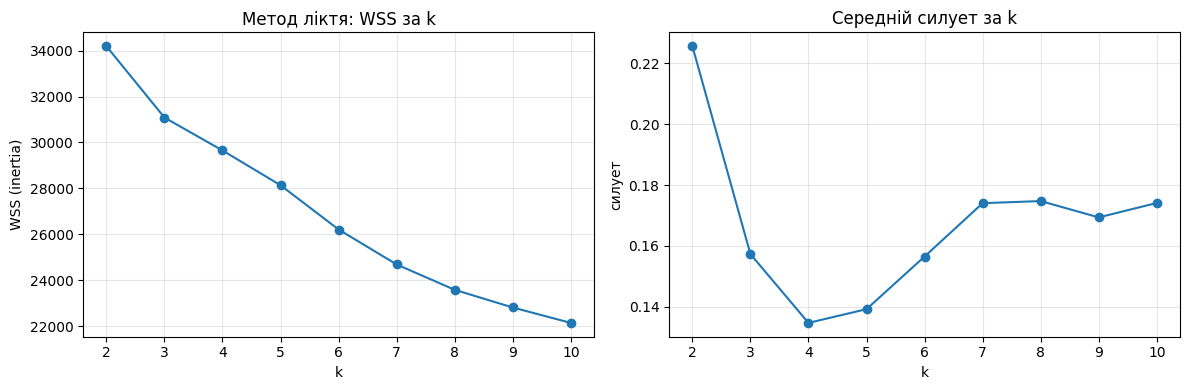

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metrics_by_k['k'], metrics_by_k['WSS'], marker='o')
axes[0].set_title('Метод ліктя: WSS за k')
axes[0].set_xlabel('k')
axes[0].set_ylabel('WSS (inertia)')
axes[0].grid(alpha=0.3)

axes[1].plot(metrics_by_k['k'], metrics_by_k['silhouette'], marker='o')
axes[1].set_title('Середній силует за k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('силует')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# МОЄ РІШЕННЯ: k = 3. Лікоть на WSS один і він на 3; ARI між сідами 42 і 7
# дорівнює 1.000, тобто розбиття не залежить від старту; k = 7 дає трохи
# вищий силует, але ARI 0.674 і кластер з 49 осіб.

k_chosen = 3
km_final = KMeans(n_clusters=k_chosen, n_init=10, random_state=42)
labels_final = km_final.fit_predict(X_scaled_v2)

sil_final = silhouette_score(X_scaled_v2, labels_final)
print('k = %d, силует %.4f, WSS %.1f' % (k_chosen, sil_final, km_final.inertia_))
print('розміри:', pd.Series(labels_final).value_counts().sort_index().to_dict())

df_clean['cluster_final'] = labels_final

k = 3, силует 0.1573, WSS 31085.9
розміри: {0: 900, 1: 537, 2: 582}


In [42]:
# Профіль у сирих одиницях: це те, що читає маркетинг
prof_final = df_clean.groupby('cluster_final')[
    ['Income', 'TotalMnt', 'TotalPurchases', 'NumDealsPurchases',
     'NumCatalogPurchases', 'NumWebVisitsMonth',
     'Kidhome', 'Teenhome', 'Year_Birth', 'Recency']].median()
prof_final['n'] = df_clean['cluster_final'].value_counts().sort_index()
prof_final['share_%'] = (prof_final['n'] / len(df_clean) * 100).round(1)
print(prof_final.round(1).to_string())

                Income  TotalMnt  TotalPurchases  NumDealsPurchases  NumCatalogPurchases  NumWebVisitsMonth  Kidhome  Teenhome  Year_Birth  Recency    n  share_%
cluster_final                                                                                                                                                    
0              34034.5      62.0             5.0                2.0                  0.0                7.0      1.0       0.0      1973.0     49.0  900     44.6
1              75825.0    1338.0            20.0                1.0                  6.0                2.0      0.0       0.0      1969.0     50.0  537     26.6
2              57909.0     632.5            16.0                3.0                  2.0                6.0      0.0       1.0      1964.0     50.0  582     28.8


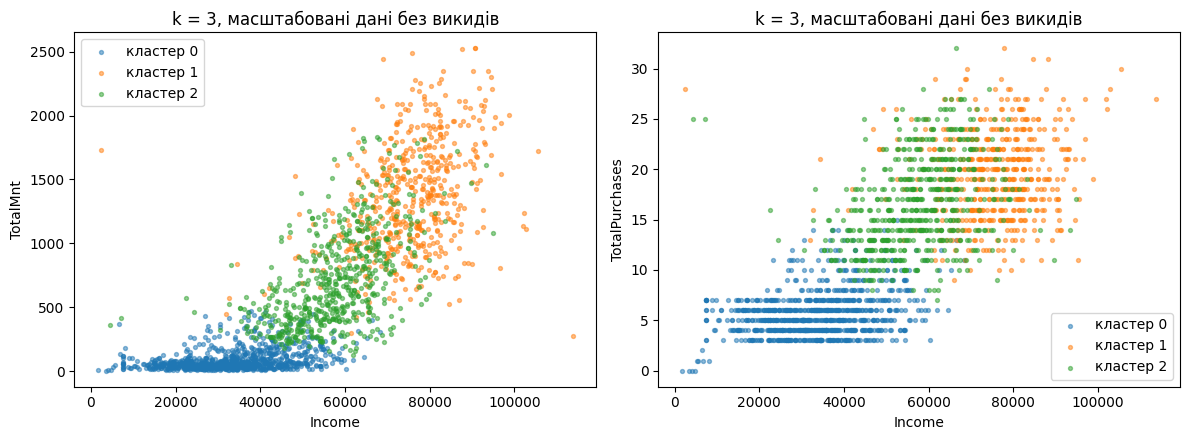

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (xc, yc) in zip(axes, [('Income', 'TotalMnt'),
                               ('Income', 'TotalPurchases')]):
    for c in sorted(df_clean['cluster_final'].unique()):
        sub = df_clean[df_clean['cluster_final'] == c]
        ax.scatter(sub[xc], sub[yc], s=8, alpha=0.5, label='кластер %d' % c)
    ax.set_xlabel(xc)
    ax.set_ylabel(yc)
    ax.set_title('k = %d, масштабовані дані без викидів' % k_chosen)
    ax.legend()
plt.tight_layout()
plt.show()

Лікоть я будувала на масштабованих даних без викидів, k від 2 до 10, і поруч рахувала силует, Calinski-Harabasz, Davies-Bouldin і ARI між двома random_state.

Крива WSS має один злам: падіння 3105 на переході 2 → 3 і 1433 на переході 3 → 4, далі крива майже пряма. Другого ліктя немає. Тому я взяла k = 3, силует 0.1573, WSS 31085.9, розміри 900, 537, 582.

Метрики розійшлися, і це очікувано: силует і Calinski-Harabasz обрали k = 2 (нижній край діапазону), Davies-Bouldin обрав k = 7. Я перевірила k = 7: силует там вищий (0.1747) і DB найнижчий (1.658), але ARI між сідами 42 і 7 дорівнює 0.674, тобто склад кластерів залежить від випадкового старту, і один кластер має 49 клієнтів. При k = 3 ARI дорівнює 1.000. Нестабільне розбиття я здавати не можу, тому вибір на k = 3.

Сегменти читаються так:

Кластер 0, 900 клієнтів (44.6%). Дохід 34034, витрати 62, 5 покупок, 7 візитів
на сайт на місяць, одна мала дитина. Дивиться і не купує.
Кластер 2, 582 клієнти (28.8%). Дохід 57909, витрати 632, 16 покупок, 3 з них за акцією, підліток у домі. Полює на знижки.
Кластер 1, 537 клієнтів (26.6%). Дохід 75825, витрати 1338, 20 покупок, 6 з каталогу, 2 візити на сайт, дітей немає. Купує багато і не шукає знижок.

NumWebVisitsMonth падає з 7 до 2 від першого сегмента до третього: візити на сайт зворотні до покупок. Це поведінкова відмінність, якої розбиття без масштабування (завдання 4) не бачило взагалі.

**Завдання 9.** Використовуючи методи `scipy` `dendrogram, linkage, fcluster`
1. Побудуйте ієрархічну агломеративну кластеризацію з `single linkage` на даних невідмасштабованих, але з прибраним викидом.
2. Візуалізуйте дендрограму. При візуалізації обовʼязково задайте параметр `truncate_mode='lastp'` - це обріже дендрограму, без цього вона буде завелика, бо у нас тут даних суттєво більше, ніж в лекції.
3. Проаналізуйте дендрограму та побудуйте варіанти плоских кластеризацій з `fcluster` на 2 і 3 кластери. Візуалізуйте результати кожної з цих кластеризацій та зробіть висновок. Чи вважаєте ви якусь з цих кластеризацій вдалою? Що спостерігаєте з цих кластеризацій?
4. Порахуйте мерику силуету для цього методу кластеризації.

In [44]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Немасштабовані дані без викидів, ті самі 22 колонки
X_single = df_clean[X_cols].values
print('X_single:', X_single.shape)

Z_single = linkage(X_single, method='single')   # метрика за замовчуванням евклідова
print('злиттів:', Z_single.shape[0])
print('висоти останніх 10 злиттів:', np.round(Z_single[-10:, 2], 1))

X_single: (2019, 22)
злиттів: 2018
висоти останніх 10 злиттів: [ 870.2  945.5  949.3 1331.3 1772.1 1865.8 1908.  2933.1 3266.7 8334.7]


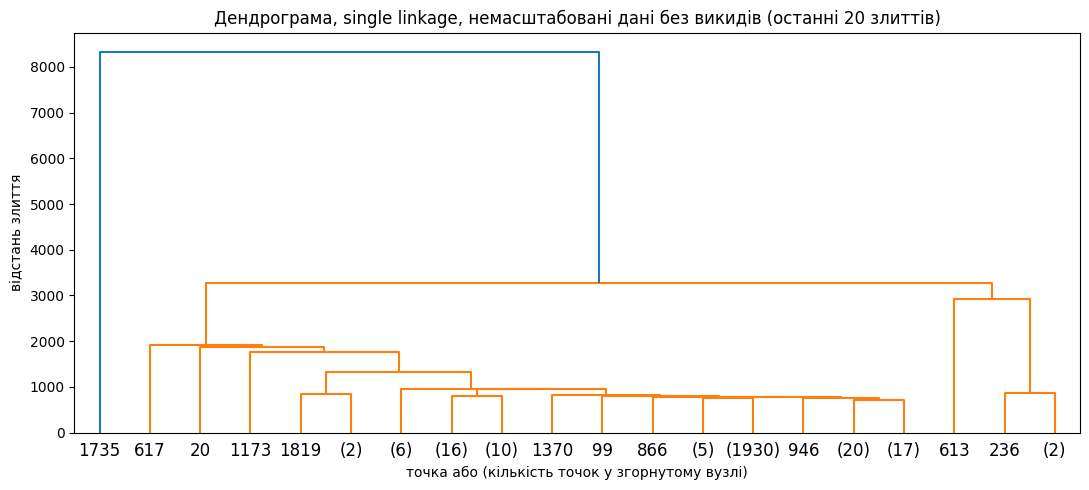

In [45]:
plt.figure(figsize=(11, 5))
dendrogram(Z_single, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.title('Дендрограма, single linkage, немасштабовані дані без викидів (останні 20 злиттів)')
plt.xlabel('точка або (кількість точок у згорнутому вузлі)')
plt.ylabel('відстань злиття')
plt.tight_layout()
plt.show()

In [46]:
labels_single_2 = fcluster(Z_single, t=2, criterion='maxclust')
labels_single_3 = fcluster(Z_single, t=3, criterion='maxclust')

for name, lab in [('2 кластери', labels_single_2), ('3 кластери', labels_single_3)]:
    print(name, dict(pd.Series(lab).value_counts().sort_index()),
          'силует %.4f' % silhouette_score(X_single, lab))

2 кластери {1: np.int64(2018), 2: np.int64(1)} силует 0.5548
3 кластери {1: np.int64(2014), 2: np.int64(4), 3: np.int64(1)} силует 0.4477


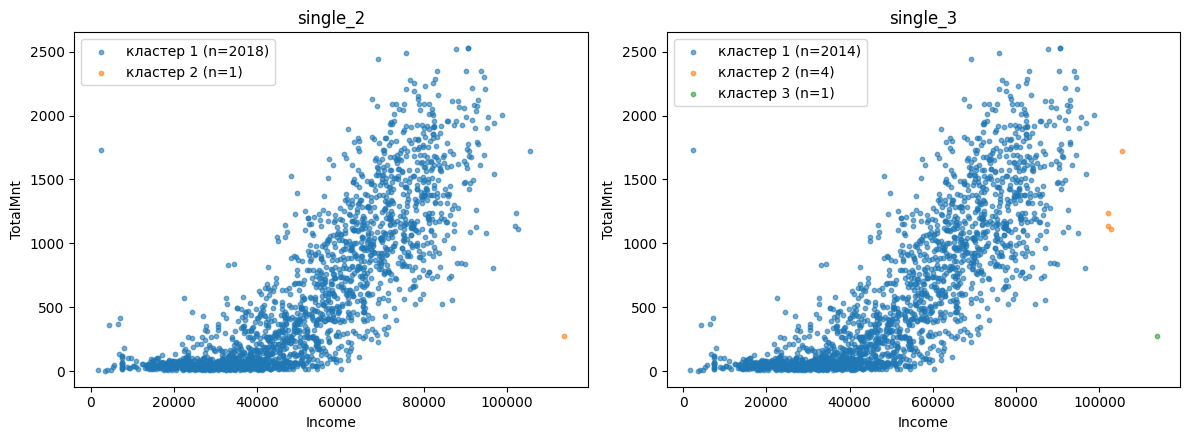

In [47]:
df_clean['single_2'] = labels_single_2
df_clean['single_3'] = labels_single_3

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ['single_2', 'single_3']):
    for c in sorted(df_clean[col].unique()):
        sub = df_clean[df_clean[col] == c]
        ax.scatter(sub['Income'], sub['TotalMnt'], s=10, alpha=0.6,
                   label='кластер %d (n=%d)' % (c, len(sub)))
    ax.set_xlabel('Income')
    ax.set_ylabel('TotalMnt')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [48]:
# Профіль: що саме відокремилось
for col in ['single_2', 'single_3']:
    print('\n', col)
    print(df_clean.groupby(col)[['Income', 'TotalMnt', 'TotalPurchases']]
          .median().round(1).to_string())


 single_2
            Income  TotalMnt  TotalPurchases
single_2                                    
1          51400.5     397.0            12.0
2         113734.0     277.0            27.0

 single_3
            Income  TotalMnt  TotalPurchases
single_3                                    
1          51371.0     396.0            12.0
2         102426.0    1187.5            27.5
3         113734.0     277.0            27.0


Я побудувала linkage(X, method='single') на немасштабованих даних без викидів, 2019 рядків і ті самі 22 колонки. Дендрограму обрізала через truncate_mode='lastp' з p=20: 10 замало, щоб побачити розгалуження, 50 нечитабельно.

Жодна з двох кластеризацій невдала. fcluster на 2 кластери дав розміри 2018 і 1, на 3 кластери 2014, 4 і 1. Алгоритм не поділив клієнтів, він відрізав найдальші точки по одній.

Причина це ланцюжковий ефект single linkage: відстань між групами дорівнює мінімуму по всіх парах точок, тож дві групи зливаються, щойно знайдеться одна пара близьких точок. У щільній хмарі така пара є завжди. Немасштабовані дані це посилюють: Income тримає 99.97 % дисперсії, а доходи йдуть майже суцільно від 1730 до 113734, тож у кожного клієнта є близький сусід за доходом. Висоти останніх злиттів показують те саме: 8334.7 на останньому проти 870 до 2933 на восьми попередніх, тобто одна велика відсічка і щільна маса під нею.

Силует при цьому дорівнює 0.5548 на двох кластерах і 0.4477 на трьох, проти 0.1573 у KMeans з k = 3. Тобто гірша кластеризація отримала втричі вищу оцінку. Силует самотньої точки за домовленістю дорівнює 0, а решта 2018 точок лежать в одному кластері, для якого b це відстань до далекої точки, і формула нагороджує за те, що всі разом.

**Висновок:** силует не можна читати без розмірів кластерів. Високе число при розбитті 2018 на 1 нічого не означає.

**Завдання 10.**
1. Використайте метод кластеризації, який ми не використовували в попередніх завданнях цього ДЗ (може бути ієрархічна кластеризація з іншим способом звʼязності або інші методи sklearn).
2. Порахуйте мер=трику силуету і візуалізуйте результат кластеризації. Зробіть висновок про те, чи могла б ця кластеризація бути корисною?

In [51]:
from sklearn.mixture import GaussianMixture

bic_rows = []
for k in range(2, 9):
    gm = GaussianMixture(n_components=k, covariance_type='full',
                         n_init=5, random_state=42).fit(X_scaled_v2)
    lab = gm.predict(X_scaled_v2)
    bic_rows.append({
        'k': k,
        'BIC': gm.bic(X_scaled_v2),
        'siluette': silhouette_score(X_scaled_v2, lab),
        'розміри': sorted(pd.Series(lab).value_counts().tolist()),
    })

bic_df = pd.DataFrame(bic_rows)
print(bic_df.round(4).to_string(index=False))

 k         BIC  siluette                                 розміри
 2  45336.1123    0.1544                             [750, 1269]
 3  45261.6706    0.1146                         [383, 670, 966]
 4  -3455.6515    0.0675                    [450, 458, 552, 559]
 5 -19420.1532    0.1159               [319, 334, 374, 374, 618]
 6 -30905.4552    0.1315           [19, 180, 327, 381, 431, 681]
 7 -29517.4053    0.0882      [40, 145, 206, 232, 275, 330, 791]
 8 -40434.9666    0.1602 [49, 129, 137, 199, 239, 252, 479, 535]


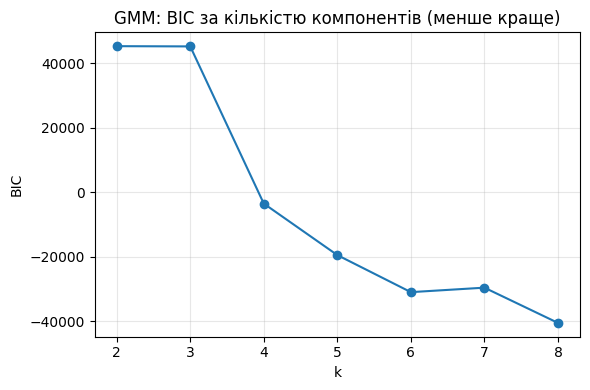

In [50]:
plt.figure(figsize=(6, 4))
plt.plot(bic_df['k'], bic_df['BIC'], marker='o')
plt.title('GMM: BIC за кількістю компонентів (менше краще)')
plt.xlabel('k')
plt.ylabel('BIC')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
# МОЄ РІШЕННЯ:
# GMM лише на неперервних ознаках. Бінарні колонки (HasPartner, п'ять Edu_*)
# і лічильники з трьома значеннями роблять коваріацію виродженою, щільність вибухає, і BIC перестає бути числом про якість кластерів.

cols_cont = [
    'Income', 'Recency',
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases',
    'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
    'Year_Birth',
]

X_cont = df_clean[cols_cont].copy()
scaler_gmm = StandardScaler()                  # свій скейлер на своєму наборі колонок
X_cont_scaled = scaler_gmm.fit_transform(X_cont)
print('X_cont_scaled:', X_cont_scaled.shape)

X_cont_scaled: (2019, 14)


 k        BIC  silhouette                                розміри
 2 44775.8162      0.2704                            [918, 1101]
 3 39904.7234      0.1484                        [560, 673, 786]
 4 38028.4797      0.1295                   [323, 492, 546, 658]
 5 37307.7308      0.0589              [270, 323, 440, 456, 530]
 6 34071.5203      0.0622         [167, 204, 230, 396, 417, 605]
 7 32695.7438      0.0106     [79, 173, 252, 323, 369, 409, 414]
 8 32273.3737      0.0114 [75, 88, 159, 289, 311, 333, 359, 405]


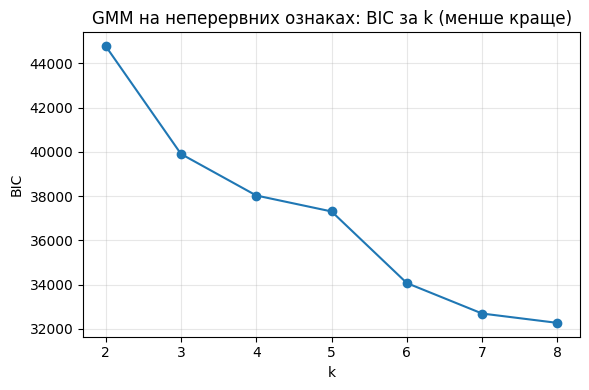

In [53]:
gmm_rows = []
for k in range(2, 9):
    gm = GaussianMixture(n_components=k, covariance_type='full',
                         n_init=5, random_state=42).fit(X_cont_scaled)
    lab = gm.predict(X_cont_scaled)
    gmm_rows.append({
        'k': k,
        'BIC': gm.bic(X_cont_scaled),
        'silhouette': silhouette_score(X_cont_scaled, lab),
        'розміри': sorted(pd.Series(lab).value_counts().tolist()),
    })

gmm_df = pd.DataFrame(gmm_rows)
print(gmm_df.round(4).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(gmm_df['k'], gmm_df['BIC'], marker='o')
plt.title('GMM на неперервних ознаках: BIC за k (менше краще)')
plt.xlabel('k'); plt.ylabel('BIC'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [57]:
# МОЄ РІШЕННЯ: k = 4. Лікоть BIC: падіння 1877 на 3 -> 4 і лише 721 на 4 -> 5.
# При k = 5 силует падає з 0.1295 до 0.0589, тобто п'ятий компонент
# розрізає наявні кластери, а не знаходить новий.

gmm4 = GaussianMixture(n_components=4, covariance_type='full',
                       n_init=5, random_state=42).fit(X_cont_scaled)
labels_gmm4 = gmm4.predict(X_cont_scaled)

sil_gmm4 = silhouette_score(X_cont_scaled, labels_gmm4)
print('GMM k=4: силует %.4f' % sil_gmm4)
print('KMeans k=3 (22 колонки): силует %.4f' % sil_final)
print('розміри:', pd.Series(labels_gmm4).value_counts().sort_index().to_dict())
print('ARI з KMeans k=3: %.3f'
      % adjusted_rand_score(labels_gmm4, df_clean['cluster_final']))

GMM k=4: силует 0.1295
KMeans k=3 (22 колонки): силует 0.1573
розміри: {0: 492, 1: 546, 2: 323, 3: 658}
ARI з KMeans k=3: 0.512


найбільша ймовірність: медіана 1.000
клієнтів з упевненістю нижче 0.9: 7.4 %
клієнтів з упевненістю нижче 0.6: 0.9 %


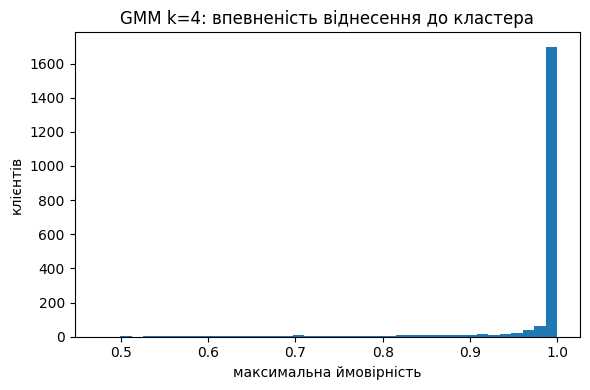

In [58]:
# М'яке членство: те, чого KMeans не дає взагалі
proba4 = gmm4.predict_proba(X_cont_scaled)
max_p = proba4.max(axis=1)
print('найбільша ймовірність: медіана %.3f' % np.median(max_p))
print('клієнтів з упевненістю нижче 0.9: %.1f %%' % (100 * (max_p < 0.9).mean()))
print('клієнтів з упевненістю нижче 0.6: %.1f %%' % (100 * (max_p < 0.6).mean()))

plt.figure(figsize=(6, 4))
plt.hist(max_p, bins=40)
plt.title('GMM k=4: впевненість віднесення до кластера')
plt.xlabel('максимальна ймовірність'); plt.ylabel('клієнтів')
plt.tight_layout(); plt.show()

In [59]:
df_clean['cluster_gmm4'] = labels_gmm4

prof_gmm = df_clean.groupby('cluster_gmm4')[
    ['Income', 'TotalMnt', 'TotalPurchases', 'NumDealsPurchases',
     'NumCatalogPurchases', 'NumWebVisitsMonth',
     'Kidhome', 'Teenhome', 'Year_Birth']].median()
prof_gmm['n'] = df_clean['cluster_gmm4'].value_counts().sort_index()
print(prof_gmm.round(1).to_string())

# Де GMM розійшовся з KMeans
print('\nперетин KMeans k=3 (рядки) і GMM k=4 (колонки):')
print(pd.crosstab(df_clean['cluster_final'], df_clean['cluster_gmm4']).to_string())

               Income  TotalMnt  TotalPurchases  NumDealsPurchases  NumCatalogPurchases  NumWebVisitsMonth  Kidhome  Teenhome  Year_Birth    n
cluster_gmm4                                                                                                                                  
0             75766.5    1273.0            19.0                1.0                  5.0                2.0      0.0       0.0      1968.0  492
1             48794.0     315.0            11.5                3.0                  1.0                6.0      0.0       1.0      1969.0  546
2             63684.0    1053.0            19.0                3.0                  4.0                6.0      0.0       1.0      1967.0  323
3             31723.5      48.0             5.0                1.0                  0.0                7.0      1.0       0.0      1973.0  658

перетин KMeans k=3 (рядки) і GMM k=4 (колонки):
cluster_gmm4     0    1    2    3
cluster_final                    
0                1  229  

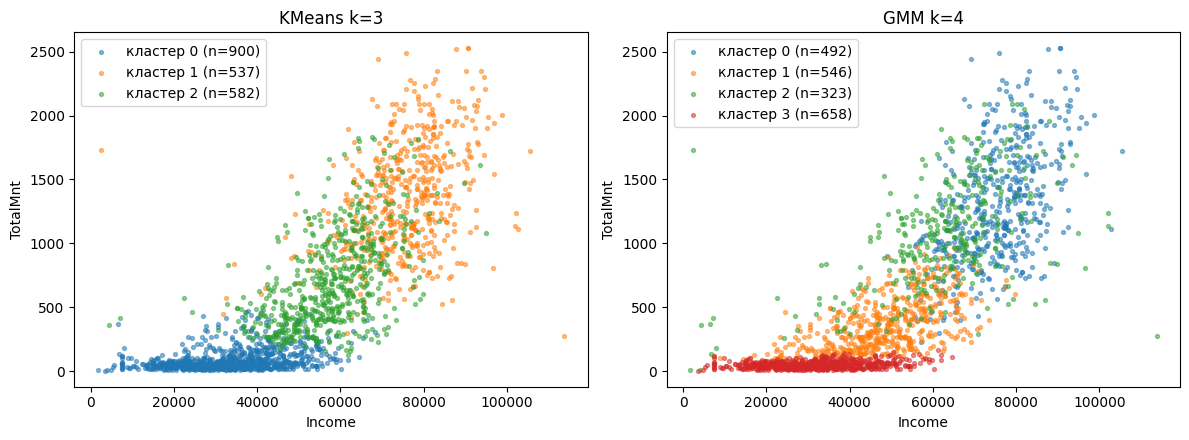

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, ttl in zip(axes, ['cluster_final', 'cluster_gmm4'],
                        ['KMeans k=3', 'GMM k=4']):
    for c in sorted(df_clean[col].unique()):
        sub = df_clean[df_clean[col] == c]
        ax.scatter(sub['Income'], sub['TotalMnt'], s=8, alpha=0.5,
                   label='кластер %d (n=%d)' % (c, len(sub)))
    ax.set_title(ttl); ax.set_xlabel('Income'); ax.set_ylabel('TotalMnt'); ax.legend()
plt.tight_layout(); plt.show()

Я взяла Gaussian Mixture Model (GMM) з алгоритмом EM. Він описує кластер не тільки центром, а й власною коваріацією, тобто бачить витягнуті еліпси, і дає м'яке членство через predict_proba.

Перша спроба на всіх 22 колонках провалилась, і це головний результат завдання. BIC упав з 45262 при k = 3 до -3456 при k = 4 і далі до -40435 при k = 8, без мінімуму. Від'ємний BIC означає величезну додатну логарифмічну правдоподібність: шість бінарних колонок (HasPartner, п'ять Edu_*) дають компонентам нульову дисперсію в цих напрямках, щільність вибухає, і BIC починає нагороджувати вироджені кишені замість кластерів. У розмірах це видно прямо: при k = 6 з'являється компонент з 19 точок. GMM припускає неперервні ознаки, і ламається на one-hot мовчки, без попередження.

Тому я перезапустила GMM на 14 неперервних колонках. BIC став додатним і читається як лікоть: падіння 4871 на 2 → 3, 1877 на 3 → 4 і лише 721 на 4 → 5. Я взяла k = 4: п'ятий компонент майже не покращує правдоподібність, а силует при ньому падає з 0.1295 до 0.0589.

Силует GMM k = 4 дорівнює 0.1295 проти 0.1573 у KMeans k = 3, ARI між ними 0.512. Це інше розбиття, а не те саме з іншими номерами, і корисне воно тим, що знайшло групу, яку KMeans не виділив: 323 клієнти з доходом 63684 і витратами 1053, які купують за акціями (3 покупки проти 1) і заходять на сайт 6 разів на місяць проти 2 у найбагатшого сегмента. Це мисливці за знижками з високим чеком, і для маркетингу вони цінні окремо: їм потрібна акція, а не каталог. KMeans розкидав їх між двома своїми кластерами (97 і 212).

Чи корисна ця кластеризація: так, як доповнення, не як заміна. GMM бачить витягнуті групи, які KMeans ріже, і дає ймовірність замість мітки. М'яке членство тут майже не знадобилось (медіана впевненості 1.000, лише 7.4 % клієнтів нижче 0.9), бо компоненти майже не перекриваються. Його цінність виявиться на даних, де сегменти справді перетинаються.